# BÀI THỰC HÀNH 5: NHẬN DIỆN KHUÔN MẶT VỚI MTCNN + FACENET (CHẠY TRÊN ẢNH TĨNH)

App `Lab5.py` chạy trên webcam theo thời gian thực nên không chụp lại được để đưa vào report. Notebook này chạy **cùng pipeline trên ảnh tĩnh** và lưu hình vào `ket_qua/`.

Notebook **không viết lại thuật toán**: dùng lớp `FaceRecognitionSystem` trong `Lab5.py` (MTCNN phát hiện mặt → FaceNet tạo embedding 512 chiều chuẩn hóa L2 → cosine similarity, ngưỡng 0.7).

Pipeline:
1. **Phát hiện khuôn mặt** bằng MTCNN (hộp bao + 5 điểm mốc)
2. **Trích xuất đặc trưng** bằng FaceNet → vector 512 chiều, ‖e‖ = 1
3. **So khớp** bằng cosine similarity với cơ sở dữ liệu: > 0.7 → *Matched*, ≤ 0.7 → *Unknown*

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image

from Lab5 import FaceRecognitionSystem

DB_DIR = Path("du_lieu/known_faces")     # ảnh mẫu đã biết (cơ sở dữ liệu)
TEST_DIR = Path("du_lieu/kiem_tra")      # ảnh cần nhận diện thêm (nếu có)
OUTPUT_DIR = Path("ket_qua")
OUTPUT_DIR.mkdir(exist_ok=True)
TEST_DIR.mkdir(exist_ok=True)

def bgr2rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

recognizer = FaceRecognitionSystem(db_dir=str(DB_DIR), similarity_threshold=0.7, device="cpu")
print("Người trong cơ sở dữ liệu:", list(recognizer.database))

/Users/mac/Documents/Edu/nam_ba/ComputerVision/CV_Labs/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Khởi tạo] Sử dụng thiết bị tính toán: cpu
[Khởi tạo] Ngưỡng so khớp (Similarity Threshold): 0.7
[Mô hình] Đang tải mô hình MTCNN (P-Net, R-Net, O-Net)...
[Mô hình] Đang tải mô hình FaceNet (InceptionResnetV1 Pretrained VGGFace2)...



--- ĐANG NẠP CƠ SỞ DỮ LIỆU KHUÔN MẶT MẪU (2 tệp tin) ---
  [+] Đã nạp thành công: download (tệp: download.png)


  [+] Đã nạp thành công: Mau_Kiem_Thu (tệp: Mau_Kiem_Thu.jpg)
[Cơ sở dữ liệu] Hoàn tất nạp 2 ảnh của 2 người.

Người trong cơ sở dữ liệu: ['download', 'Mau_Kiem_Thu']


## 1. Phát hiện khuôn mặt bằng MTCNN

MTCNN gồm 3 mạng nối tiếp: **P-Net** đề xuất vùng ứng viên trên ảnh nhiều tỉ lệ, **R-Net** lọc bớt vùng sai, **O-Net** cho hộp bao cuối cùng và 5 điểm mốc (2 mắt, mũi, 2 khóe miệng).

Chạy `recognizer.mtcnn.detect` trên từng ảnh trong cơ sở dữ liệu. Không tìm thấy mặt thì MTCNN trả về `None`. Nếu MTCNN báo có mặt ở chỗ không phải mặt người thì đó là **phát hiện nhầm (false positive)**: ngưỡng `thresholds=[0.6, 0.7, 0.7]` của 3 mạng chưa đủ chặt với ảnh đó.

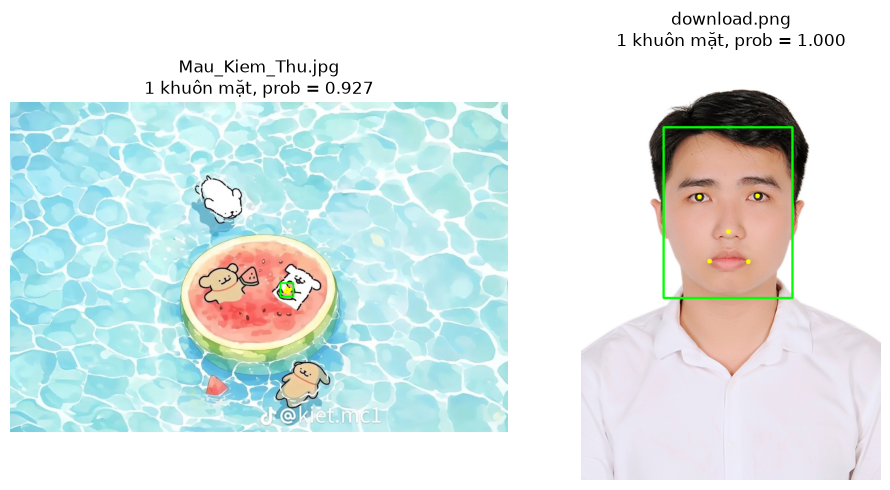

In [2]:
db_files = sorted(p for p in DB_DIR.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp", ".webp"))
fig, axes = plt.subplots(1, len(db_files), figsize=(5 * len(db_files), 5), squeeze=False)
for ax, path in zip(axes[0], db_files):
    img = cv2.imread(str(path))
    boxes, probs, landmarks = recognizer.mtcnn.detect(Image.fromarray(bgr2rgb(img)), landmarks=True)
    ve = img.copy()
    if boxes is None:
        tieu_de = f"{path.name}\nKhông phát hiện khuôn mặt"
    else:
        for box, prob, lm in zip(boxes, probs, landmarks):
            x1, y1, x2, y2 = [int(v) for v in box]
            cv2.rectangle(ve, (x1, y1), (x2, y2), (0, 255, 0), 3)
            for px, py in lm:
                cv2.circle(ve, (int(px), int(py)), 5, (0, 255, 255), -1)
        tieu_de = f"{path.name}\n{len(boxes)} khuôn mặt, prob = {probs[0]:.3f}"
    ax.imshow(bgr2rgb(ve)); ax.set_title(tieu_de); ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai1_mtcnn_phat_hien.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Trích xuất đặc trưng bằng FaceNet

MTCNN cắt và căn khuôn mặt về 160×160, rồi FaceNet (Inception-ResNet-v1, huấn luyện trên VGGFace2 bằng Triplet Loss) biến khuôn mặt thành vector 512 chiều. Vector được chuẩn hóa L2 (`F.normalize`) nên ‖e‖ = 1, khi đó cosine similarity chỉ còn là tích vô hướng.

Ảnh: download.png  |  kích thước embedding: (512,)  |  ‖e‖ = 1.0000


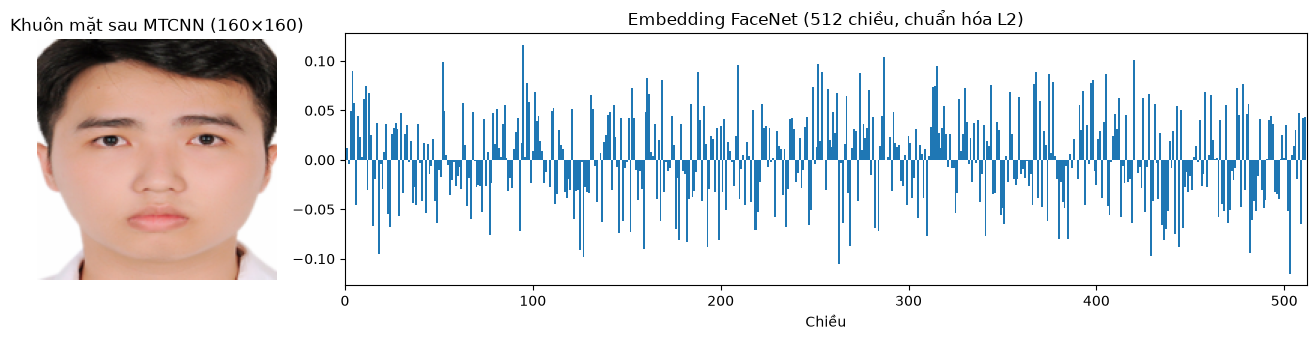

In [3]:
# Chọn ảnh mẫu là ảnh có độ tin cậy phát hiện mặt (prob) cao nhất trong cơ sở dữ liệu
def prob_cao_nhat(p):
    _, probs = recognizer.mtcnn.detect(Image.open(p).convert("RGB"))
    return -1.0 if probs is None or probs[0] is None else float(max(probs))
anh_mau = max(db_files, key=prob_cao_nhat)
anh = Image.open(anh_mau).convert("RGB")
face = recognizer.mtcnn(anh)[0:1]                 # tensor (1, 3, 160, 160), giống load_database
with torch.no_grad():
    emb = F.normalize(recognizer.facenet(face), p=2, dim=1)[0]
print(f"Ảnh: {anh_mau.name}  |  kích thước embedding: {tuple(emb.shape)}  |  ‖e‖ = {emb.norm():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [1, 4]})
mat_160 = ((face[0].permute(1, 2, 0).numpy() + 1) / 2).clip(0, 1)   # post_process đưa pixel về [-1, 1]
axes[0].imshow(mat_160); axes[0].set_title("Khuôn mặt sau MTCNN (160×160)"); axes[0].axis("off")
axes[1].bar(range(512), emb.numpy(), width=1.0)
axes[1].set_title("Embedding FaceNet (512 chiều, chuẩn hóa L2)")
axes[1].set_xlabel("Chiều"); axes[1].set_xlim(0, 512)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai2_facenet_embedding.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. So khớp bằng cosine similarity (ngưỡng 0.7)

**Ảnh kiểm tra.** Cơ sở dữ liệu hiện chỉ có 1 ảnh người thật, chưa có ảnh khác của cùng người hay ảnh người lạ. Vì vậy cell dưới **tự tạo vài biến thể** từ ảnh mẫu (lật ngang, giảm sáng, làm mờ) bằng các phép xử lý ảnh đã học ở Lab1–2, chỉ để có ảnh đầu vào thử. Các ảnh khác trong cơ sở dữ liệu cũng được đưa vào để xem kết quả so khớp.

Muốn thử ảnh thật (ảnh khác của cùng người, ảnh người lạ) thì bỏ vào `du_lieu/kiem_tra/` rồi chạy lại; notebook tự nạp.

Mỗi ảnh đi qua `recognizer.process_frame`, đúng hàm mà app webcam gọi cho từng khung hình: khung **xanh** = Matched, khung **đỏ** = Unknown.

In [4]:
goc = cv2.imread(str(anh_mau))
anh_kiem_tra = {
    "Ảnh mẫu (gốc)": goc,
    "Lật ngang": cv2.flip(goc, 1),
    "Giảm sáng (x0.5)": np.clip(goc.astype(np.float32) * 0.5, 0, 255).astype(np.uint8),
    "Làm mờ Gaussian 15x15": cv2.GaussianBlur(goc, (15, 15), 0),
}
for p in db_files:
    if p != anh_mau:
        anh_kiem_tra[f"{p.name} (ảnh khác trong CSDL)"] = cv2.imread(str(p))
for p in sorted(TEST_DIR.iterdir()):
    if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp", ".webp"):
        anh_kiem_tra[f"kiem_tra/{p.name}"] = cv2.imread(str(p))

ket_qua = []
for ten, img in anh_kiem_tra.items():
    annotated, dets = recognizer.process_frame(img, draw_landmarks=True)
    ket_qua.append((ten, annotated, dets))
    if not dets:
        print(f"{ten:<40} -> không phát hiện khuôn mặt")
    for d in dets:
        print(f"{ten:<40} -> {d['status']:<8} {d['name']:<12} similarity = {d['similarity']:.4f}")

Ảnh mẫu (gốc)                            -> Matched  download     similarity = 1.0000
Lật ngang                                -> Matched  download     similarity = 0.9873
Giảm sáng (x0.5)                         -> Matched  download     similarity = 0.9789


Làm mờ Gaussian 15x15                    -> Matched  download     similarity = 0.9884
Mau_Kiem_Thu.jpg (ảnh khác trong CSDL)   -> Matched  Mau_Kiem_Thu similarity = 1.0000


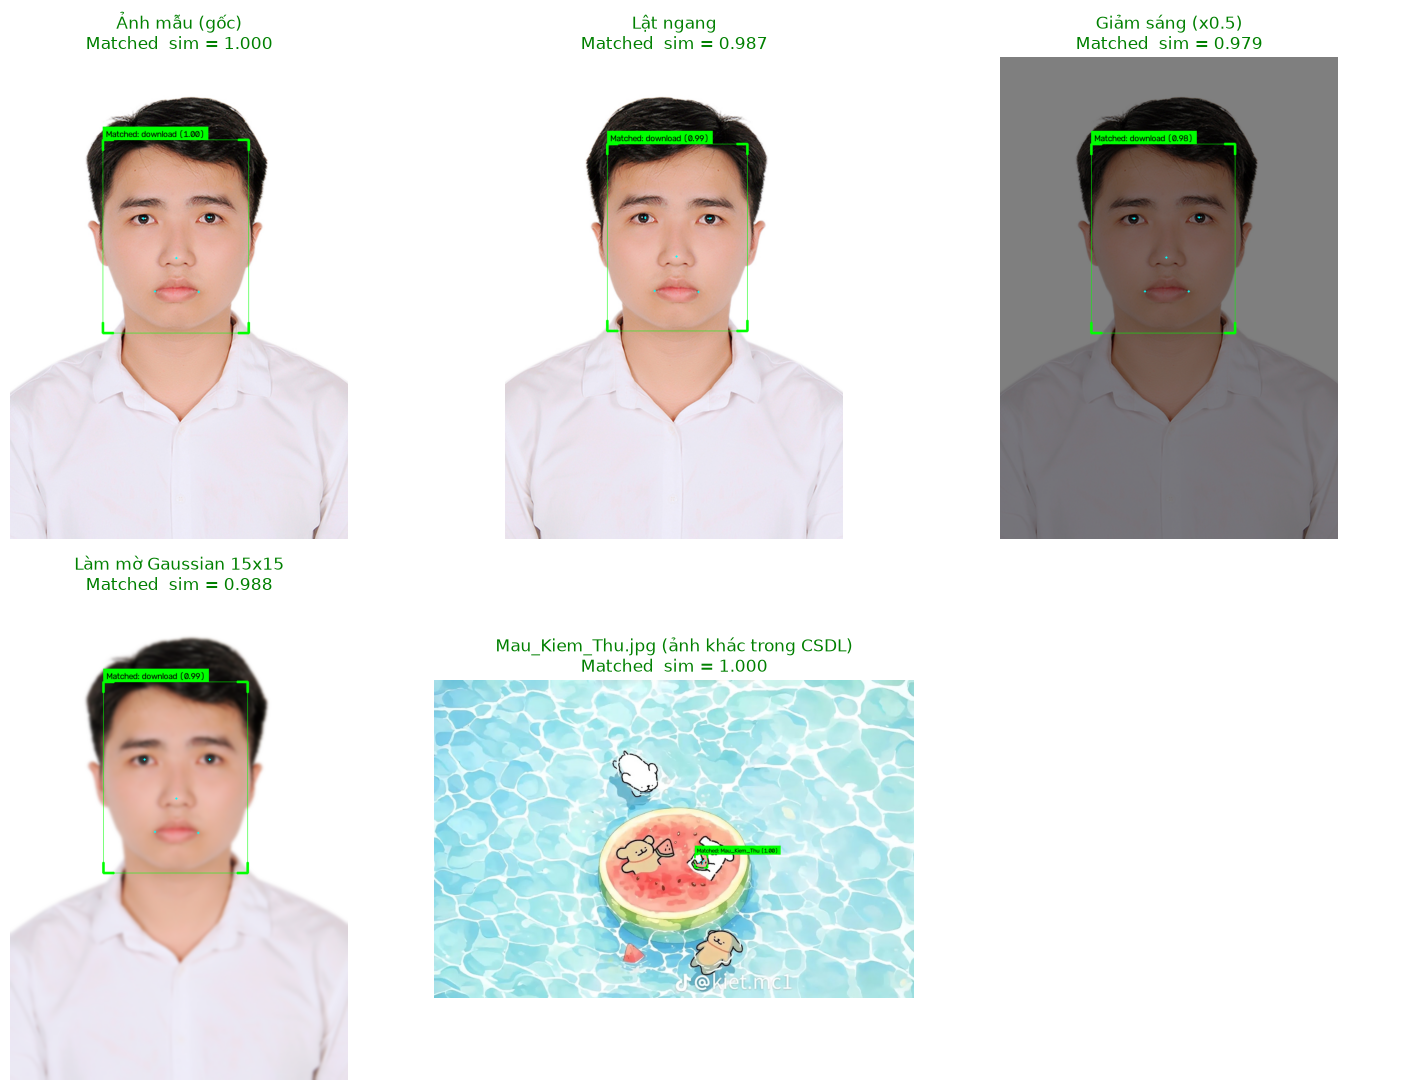

In [5]:
n = len(ket_qua)
cols = min(n, 3)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5.5 * rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, (ten, annotated, dets) in zip(axes.ravel(), ket_qua):
    ax.imshow(bgr2rgb(annotated))
    if dets:
        d = dets[0]
        mau = "green" if d["status"] == "Matched" else "red"
        ax.set_title(f"{ten}\n{d['status']}  sim = {d['similarity']:.3f}", color=mau)
    else:
        ax.set_title(f"{ten}\nKhông phát hiện khuôn mặt", color="gray")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai3_nhan_dien_anh_tinh.png", dpi=100, bbox_inches="tight")
plt.show()

### Biểu đồ similarity so với ngưỡng 0.7

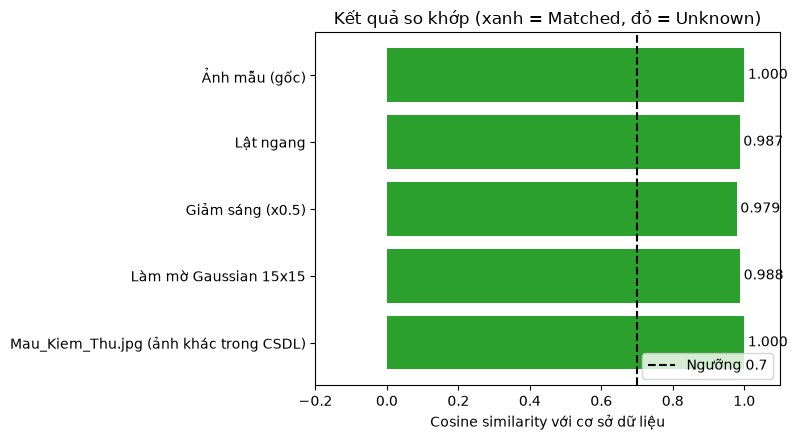

In [6]:
nhan, sims, maus = [], [], []
for ten, _, dets in ket_qua:
    for d in dets:
        nhan.append(ten); sims.append(d["similarity"])
        maus.append("tab:green" if d["status"] == "Matched" else "tab:red")

fig, ax = plt.subplots(figsize=(8, 0.6 * len(sims) + 1.5))
ax.barh(nhan, sims, color=maus)
ax.axvline(recognizer.similarity_threshold, color="black", linestyle="--", label="Ngưỡng 0.7")
for y, s in enumerate(sims):
    ax.text(s + 0.01, y, f"{s:.3f}", va="center")
ax.set_xlim(-0.2, 1.1); ax.invert_yaxis()
ax.set_xlabel("Cosine similarity với cơ sở dữ liệu")
ax.set_title("Kết quả so khớp (xanh = Matched, đỏ = Unknown)")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "bai3_similarity_nguong.png", dpi=120, bbox_inches="tight")
plt.show()

## Nhận xét

*(Viết dựa trên kết quả chạy ở trên: similarity của các biến thể so với ảnh gốc, trường hợp không có mặt người, và kết quả với ảnh trong `du_lieu/kiem_tra/` nếu có.)*